# Session 19 Solutions: Correlation and Linear Regression

Data Science with Python, Level 1, Stage 3: Statistics and ML Fundamentals

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(29)
DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
bikes = pd.read_csv(DATA_URL + "bike_rentals.csv")
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

flats = pd.read_csv(DATA_URL + "apartments.csv")

## In-Class Exercises

### In-Class Exercise 1: Strongest Link

In [2]:
num = exams.select_dtypes("number").drop(columns="student_id")
print(num.corr()["english"].drop("english").sort_values(key=abs, ascending=False).round(3))

study_hours_week    0.446
math                0.199
physics             0.178
attendance_pct      0.064
sleep_hours         0.037
Name: english, dtype: float64


### In-Class Exercise 2: Confounder Hunt

In [3]:
flats = pd.read_csv(DATA_URL + "apartments.csv")
print(round(flats["distance_center_km"].corr(flats["price_k"]), 3))
for d, g in flats.groupby("district"):
    print(d, round(g["distance_center_km"].corr(g["price_k"]), 3))

-0.457
Hillview -0.003
Northgate -0.106
Old Town -0.051
Riverside -0.007
Westpark 0.088


### In-Class Exercise 3: Predict Your Flat

In [4]:
features = ["area_m2", "rooms", "building_age", "distance_center_km", "elevator", "parking"]
X_train, X_test, y_train, y_test = train_test_split(flats[features], flats["price_k"], test_size=0.2, random_state=42)
m = LinearRegression().fit(X_train, y_train)
new = pd.DataFrame([{"area_m2": 90, "rooms": 3, "building_age": 10, "distance_center_km": 4, "elevator": True, "parking": False}])
print(m.predict(new).round(1))

[107.6]


### In-Class Exercise 4: Biggest Errors

In [5]:
features = ["area_m2", "rooms", "building_age", "distance_center_km", "elevator", "parking"]
X_train, X_test, y_train, y_test = train_test_split(flats[features], flats["price_k"], test_size=0.2, random_state=42)
m = LinearRegression().fit(X_train, y_train)
errors = (y_test - m.predict(X_test)).abs()
flats.loc[errors.nlargest(5).index, ["district", "area_m2", "price_k"]]

,district,area_m2,price_k
719,Westpark,115,202.2
54,Westpark,68,137.5
787,Riverside,35,52.5
360,Old Town,57,78.3
393,Westpark,137,88.3


## Part A: Basic

### Exercise 1: Correlations in the Bike Data

In [6]:
print(bikes[["temp_c", "humidity", "wind_kmh"]].corrwith(bikes["rentals"]).round(3))

temp_c      0.724
humidity   -0.466
wind_kmh   -0.048
dtype: float64


### Exercise 2: Study Hours and Scores

In [7]:
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
m = LinearRegression().fit(exams[["study_hours_week"]], exams["math"])
print(round(m.coef_[0], 2), round(m.intercept_, 2), round(m.score(exams[["study_hours_week"]], exams["math"]), 3))
# Each extra hour of study per week goes with about 1.5 more points in math, on average.

1.52 46.23 0.216


## Part B: Intermediate

### Exercise 3: Rank Correlation

0.798 1.0


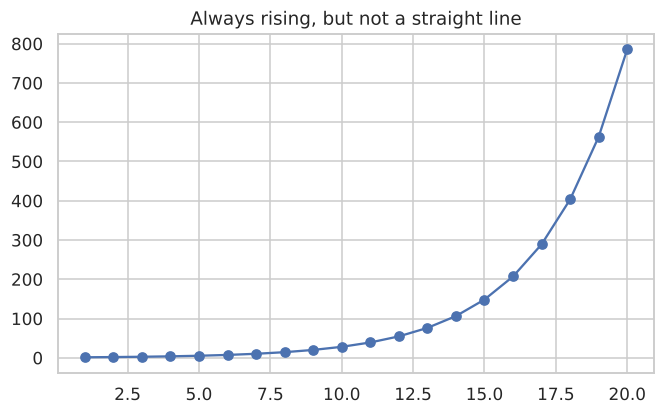

In [8]:
x = np.arange(1, 21)
y = np.exp(x / 3)
print(round(stats.pearsonr(x, y)[0], 3), round(stats.spearmanr(x, y)[0], 3))
plt.plot(x, y, marker="o")
plt.title("Always rising, but not a straight line")
plt.show()
# y always rises with x, so the ranks agree perfectly (Spearman 1); the curve is not a line, so Pearson is lower.

### Exercise 4: Several Features for Exams

In [9]:
exams = pd.read_csv(DATA_URL + "exam_scores.csv")
X = exams[["study_hours_week", "sleep_hours", "attendance_pct"]]
X_train, X_test, y_train, y_test = train_test_split(X, exams["math"], test_size=0.2, random_state=0)
m = LinearRegression().fit(X_train, y_train)
print(pd.Series(m.coef_, index=X.columns).round(2))
pred = m.predict(X_test)
print(round(r2_score(y_test, pred), 3), round(mean_absolute_error(y_test, pred), 2))

study_hours_week    1.36
sleep_hours         2.58
attendance_pct      0.13
dtype: float64
0.311 8.61


### Exercise 5: Residual Plot

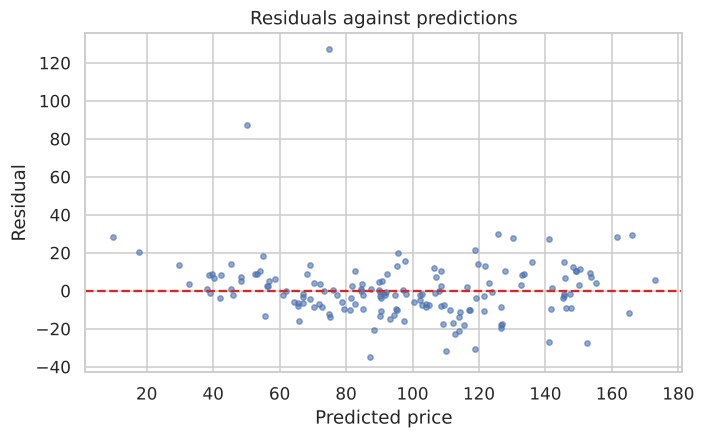

In [10]:
features = ["area_m2", "rooms", "building_age", "distance_center_km", "elevator", "parking"]
X_train, X_test, y_train, y_test = train_test_split(flats[features], flats["price_k"], test_size=0.2, random_state=42)
m = LinearRegression().fit(X_train, y_train)
pred = m.predict(X_test)
plt.scatter(pred, y_test - pred, s=12, alpha=0.6)
plt.axhline(0, color="tab:red", linestyle="--")
plt.title("Residuals against predictions")
plt.xlabel("Predicted price")
plt.ylabel("Residual")
plt.show()
# Most residuals are close to zero, but a few large positive ones are luxury flats the model cannot explain.

## Part C: Challenge

### Exercise 6: Simpson's Paradox

This reversal is called Simpson's paradox. It is the most dramatic form of confounding.

Overall: 0.859
group
G1   -0.866
G2   -0.838
G3   -0.763
dtype: float64


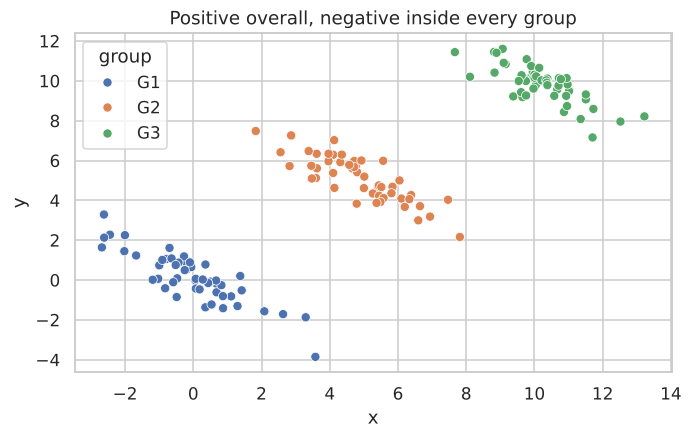

In [11]:
rows = []
for g, (cx, cy) in enumerate([(0, 0), (5, 5), (10, 10)]):
    x = rng.normal(cx, 1.2, 50)
    y = cy - 0.8 * (x - cx) + rng.normal(0, 0.6, 50)
    rows.append(pd.DataFrame({"x": x, "y": y, "group": f"G{g + 1}"}))
d = pd.concat(rows)
print("Overall:", round(d["x"].corr(d["y"]), 3))
print(d.groupby("group").apply(lambda g: round(g["x"].corr(g["y"]), 3), include_groups=False))
sns.scatterplot(data=d, x="x", y="y", hue="group")
plt.title("Positive overall, negative inside every group")
plt.show()

## Part D: Cumulative Project: Apartment Prices

### Exercise 7: Apartment Prices: A First Model

In [12]:
features_all = ["area_m2", "rooms", "floor", "building_age", "distance_center_km", "elevator", "parking"]
X_train, X_test, y_train, y_test = train_test_split(flats[features_all], flats["price_k"], test_size=0.2, random_state=42)
m = LinearRegression().fit(X_train, y_train)
pred = m.predict(X_test)
print("R2:", round(r2_score(y_test, pred), 3), "MAE:", round(mean_absolute_error(y_test, pred), 2))
baseline = np.full(len(y_test), y_train.mean())
print("Baseline MAE:", round(mean_absolute_error(y_test, baseline), 2))
coefs = pd.Series(m.coef_, index=features_all)
print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(3).round(2))
# Each kilometre further from the centre lowers the predicted price by about 8 thousand, all else equal.

R2: 0.781 MAE: 10.75
Baseline MAE: 30.03
elevator              9.64
parking               9.57
distance_center_km   -7.91
dtype: float64


## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | Strength is the size of r, whatever its sign. |
| 2 | C | Summer heat is a confounder that drives both. |
| 3 | B | Features go in; the target is what we predict. |
| 4 | B | Features are always a 2D table, even with one column. |
| 5 | B | It is the change in the prediction per km, holding the other features fixed. |